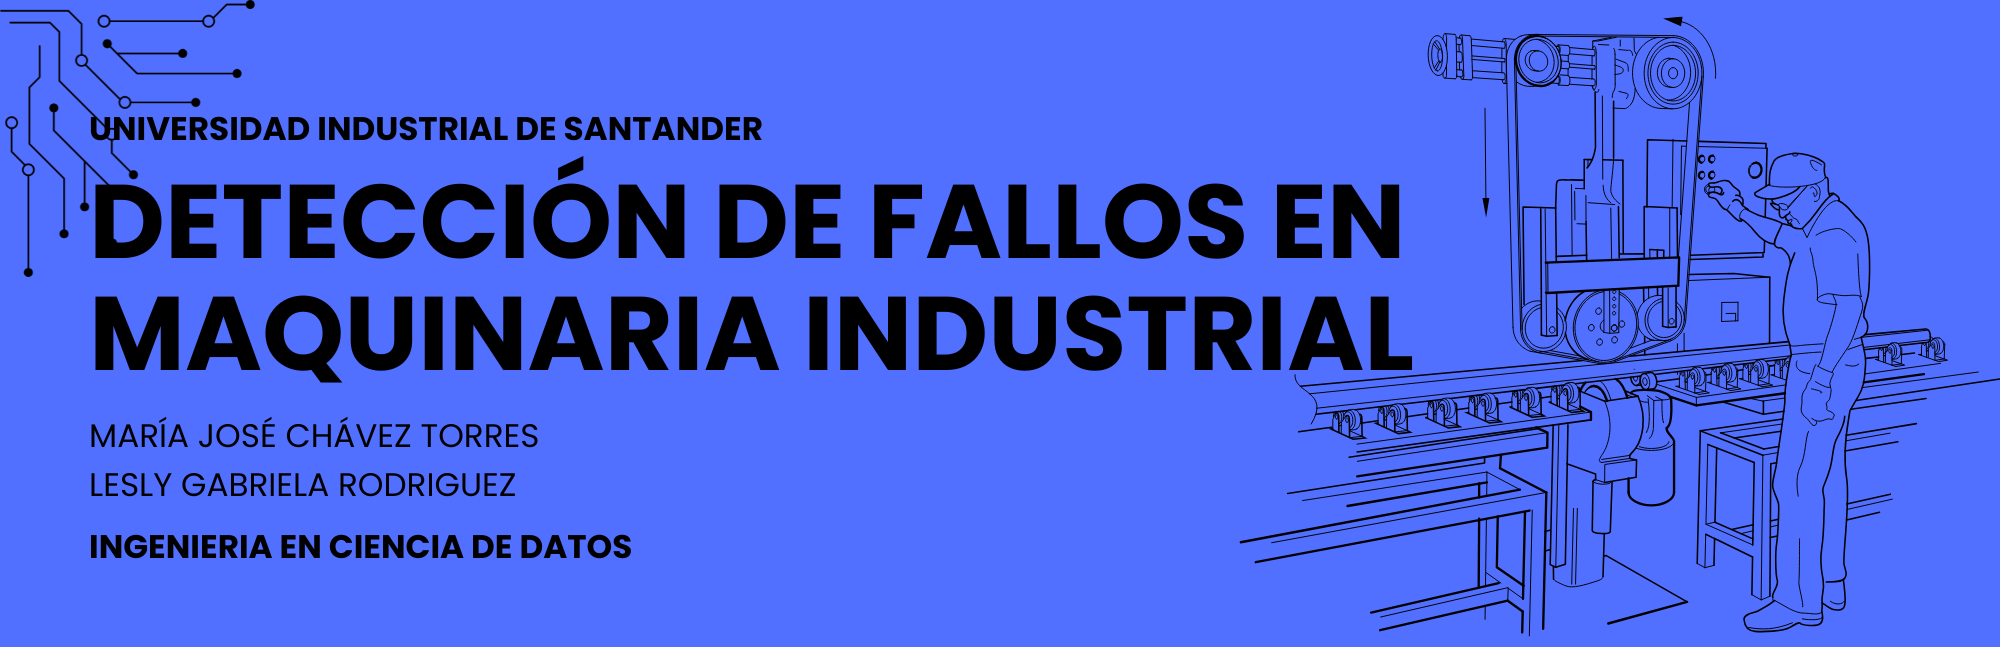



# **Proyecto de Machine Learning: Detección de Fallos en Mantenimiento Predictivo**

# **Parte 3: Regresión**

**Objetivo.** Construir y comparar modelos de regresión para predecir el torque (`Torque [Nm]`) de una máquina industrial a partir de sus demás condiciones de operación (temperaturas, velocidad de rotación, desgaste de la herramienta, `Temp_diff` y tipo de máquina). Se selecciona el mejor modelo con la métrica principal mas baja y se evalúa una sola vez en el conjunto de test.


In [ ]:
#@title librerías importadas
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
sns.set_theme()

In [ ]:
# cargar el dataset
url = 'https://raw.githubusercontent.com/gabbrod/Proyecto_ML/refs/heads/main/data/predictive_maintenance.csv'
df = pd.read_csv(url)

In [ ]:
df['Temp_diff'] = df['Process temperature [K]'] - df['Air temperature [K]']
variables_numericas = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

In [ ]:
#String a categorico variable 'Type'
dummies = pd.get_dummies(df["Type"], prefix="Type", dtype=int)
df = pd.concat([df, dummies], axis=1)

df[["Type", "Type_H", "Type_L", "Type_M"]].head(10)

,Type,Type_H,Type_L,Type_M
0,M,0,0,1
1,L,0,1,0
2,L,0,1,0
3,L,0,1,0
4,L,0,1,0
5,M,0,0,1
6,L,0,1,0
7,L,0,1,0
8,M,0,0,1
9,M,0,0,1


In [ ]:
target_aux = df["Target"].copy()
df = df.drop(columns=["UDI", "Product ID"])

In [ ]:
print(df.shape)                    # esperado: (10000, 12)
print(df.isna().sum().sum(), "valores nulos")
print(df.columns.tolist())
df.head()

(10000, 12)
0 valores nulos
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type', 'Temp_diff', 'Type_H', 'Type_L', 'Type_M']


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type,Temp_diff,Type_H,Type_L,Type_M
0,M,298.1,308.6,1551,42.8,0,0,No Failure,10.5,0,0,1
1,L,298.2,308.7,1408,46.3,3,0,No Failure,10.5,0,1,0
2,L,298.1,308.5,1498,49.4,5,0,No Failure,10.4,0,1,0
3,L,298.2,308.6,1433,39.5,7,0,No Failure,10.4,0,1,0
4,L,298.2,308.7,1408,40.0,9,0,No Failure,10.5,0,1,0


# **Fase 1: Definición del problema de regresión**

En esta parte la variable a predecir es el torque de la máquina, que es un valor continuo:

$$y_i = Torque_i \; [Nm], \qquad \hat{y}_i = f(x_i)$$

donde $x_i$ son las demás condiciones de operación de la máquina $i$ y $\hat{y}_i$ es el torque que predice el modelo.

- **Variable objetivo:** `Torque [Nm]`.
- Entradas:`Air temperature [K]`, `Process temperature [K]`, `Rotational speed [rpm]`, `Tool wear [min]`, `Temp_diff` y `Type_H`, `Type_L`, `Type_M`.
- Se excluyen: `Target` y `Failure Type`, porque son resultados de la falla y no lecturas de sensores.
- Filas: las 10.000, con y sin falla.

In [ ]:
y = df["Torque [Nm]"]
X = df.drop(columns=["Torque [Nm]", "Target", "Failure Type", "Type"])
print(X.shape, y.shape)
print(X.columns.tolist())

(10000, 8) (10000,)
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Tool wear [min]', 'Temp_diff', 'Type_H', 'Type_L', 'Type_M']


count    10000.000000
mean        39.986910
std          9.968934
min          3.800000
25%         33.200000
50%         40.100000
75%         46.800000
max         76.600000
Name: Torque [Nm], dtype: float64


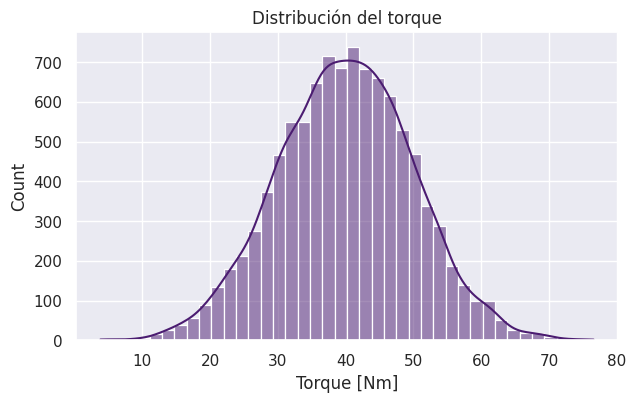

In [ ]:
#Distribucion del torque
print(y.describe())

plt.figure(figsize=(7, 4))
sns.histplot(y, bins=40, kde=True, color="#4b1c71")
plt.xlabel("Torque [Nm]")
plt.title("Distribución del torque")
plt.show()

In [ ]:
#Outliers del torque
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
n_out = ((y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr)).sum()
print(n_out, "outliers")

69 outliers


El torque tiene una distribución aproximadamente simétrica, por lo que no requiere transformación, se detectaron 69 valores atípicos por el método IQR, no se eliminan porque pueden corresponder a condiciones operativas reales exigentes.

Rotational speed [rpm]    -0.875
Process temperature [K]   -0.014
Air temperature [K]       -0.014
Type_H                    -0.005
Tool wear [min]           -0.003
Type_L                     0.001
Type_M                     0.002
Temp_diff                  0.007
Target                     0.191
Name: Torque [Nm], dtype: float64


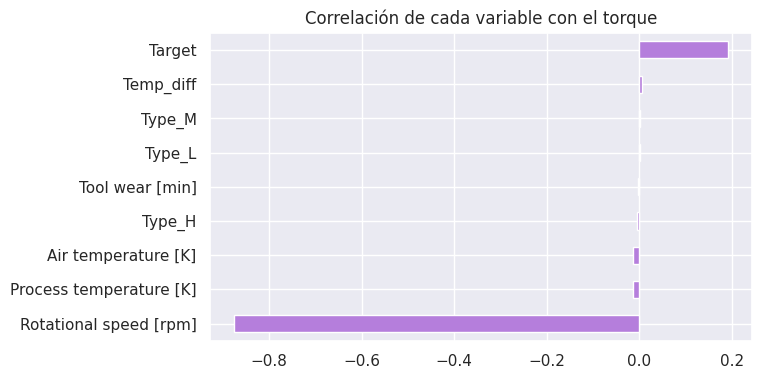

In [ ]:
#correlacion con el torque
corr = (df.drop(columns=["Failure Type", "Type"])
          .corr()["Torque [Nm]"]
          .drop("Torque [Nm]")
          .sort_values())
print(corr.round(3))

corr.plot.barh(figsize=(7, 4), color="#b57edc")
plt.title("Correlación de cada variable con el torque")
plt.show()

`Rotational speed` es la variable más relacionada con el torque, lo que indica una relación lineal fuerte. Las demás variables presentan correlaciones cercanas a cero con el torque. Esto anticipa que el modelo se apoyará principalmente en la velocidad de rotación, y que parte de esa relación es propia de la física de la máquina.

# **Fase 2: Definición de la métrica principal**

Para evaluar los modelos se miden los errores entre el torque real $y_i$ y el predicho $\hat{y}_i$, sobre $N$ muestras.

$$MSE=\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2 \qquad RMSE=\sqrt{MSE}$$

$$MAE=\frac{1}{N}\sum_{i=1}^{N}\left|y_i-\hat{y}_i\right| \qquad R^2=1-\frac{\sum_{i=1}^{N}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{N}(y_i-\bar{y})^2}$$

- **RMSE (métrica principal):** está en Nm, así que se interpreta directamente como el error típico de la predicción. Al elevar al cuadrado, penaliza más los errores grandes, que en mantenimiento predictivo son los más costosos.
- **MAE (apoyo):** error promedio en Nm, menos sensible a los valores atípicos.
- **R² (apoyo):** proporción de la variabilidad del torque que explica el modelo. Un modelo que siempre predice la media tiene R² ≈ 0.

La selección del modelo se hace con el modelo que nos de menor RMSE en validación

In [ ]:
def evaluar(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(y_real, y_pred),
            "R2": r2_score(y_real, y_pred)}

print(evaluar(y, np.full(len(y), y.mean())))
print("std:", y.std(ddof=0))

{'RMSE': np.float64(9.96843526597329), 'MAE': 7.9695070800000005, 'R2': 0.0}
std: 9.968435265973355


# **Fase 3: Partición de los datos**

Se divide e 60% train, 20% validación y 20% test, de forma aleatoria y sin estratificar, porque el torque es continuo y no hay clases. Train entrena, validación compara modelos e hiperparámetros, y test se usa una sola vez al final.

El escalado (solo para el SVR) irá dentro de un pipeline, para ajustarse únicamente con train y evitar fuga de información.

In [ ]:
X_tv, X_test, y_tv, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=0.25, random_state=SEED)

print("train:", X_train.shape, "val:", X_val.shape, "test:", X_test.shape)

train: (6000, 8) val: (2000, 8) test: (2000, 8)


In [ ]:
print(pd.DataFrame({
    "n":     [len(y_train), len(y_val), len(y_test)],
    "media": [y_train.mean(), y_val.mean(), y_test.mean()],
    "std":   [y_train.std(),  y_val.std(),  y_test.std()],
}, index=["train", "val", "test"]).round(2))

          n  media   std
train  6000  39.99  9.99
val    2000  40.06  9.94
test   2000  39.90  9.93


# **Fase 4: Modelo de referencia y modelos base**

Como referencia se usa un modelo que siempre predice la media del torque de train. Luego se entrenan los dos modelos con hiperparámetros por defecto,Random Forest y SVR. El SVR usa `RobustScaler` en las entradas y se escala también el torque.

In [ ]:
modelos = {
    "Decision tree":     DecisionTreeRegressor(random_state=SEED),
    "Random Forest":     RandomForestRegressor(random_state=SEED),
    "SVR":               make_pipeline(RobustScaler(), SVR()),
}

In [ ]:
filas = []

#aqui es donde se predice siempre la media de traij
ref = evaluar(y_val, np.full(len(y_val), y_train.mean()))
filas.append({"Modelo": "Referencia (media)", "RMSE train": np.nan,
              "RMSE val": ref["RMSE"], "MAE val": ref["MAE"], "R2 val": ref["R2"]})
for nombre, m in modelos.items():
    m.fit(X_train, y_train)
    r_tr  = evaluar(y_train, m.predict(X_train))
    r_val = evaluar(y_val,   m.predict(X_val))
    filas.append({"Modelo": nombre, "RMSE train": r_tr["RMSE"],
                  "RMSE val": r_val["RMSE"], "MAE val": r_val["MAE"],
                  "R2 val": r_val["R2"]})

tabla_base = pd.DataFrame(filas).set_index("Modelo")
tabla_base.sort_values("RMSE val")

,RMSE train,RMSE val,MAE val,R2 val
Modelo,,,,
SVR,4.044793e+00,4.075825,3.067522,0.831908
Random Forest,1.514005e+00,4.098649,3.135906,0.830020
Decision tree,7.944109e-17,5.605652,4.279150,0.682042
Referencia (media),NaN,9.941531,8.012498,-0.000055


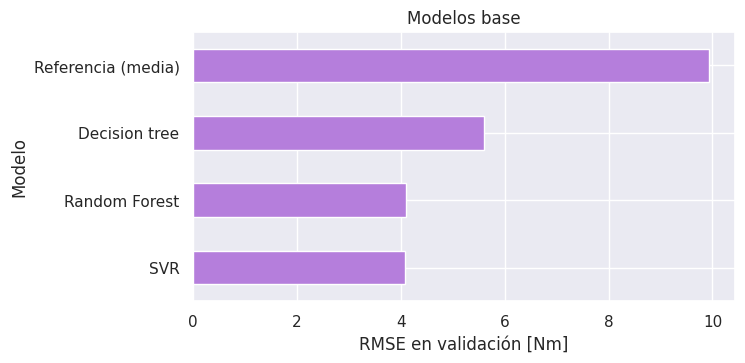

In [ ]:
tabla_base["RMSE val"].sort_values().plot.barh(figsize=(7, 3.5), color="#b57edc")
plt.xlabel("RMSE en validación [Nm]")
plt.title("Modelos base")
plt.show()

La referencia da un RMSE de = 9,94 Nm y R² ≈ 0.El Decision tree obtiene un RSME de 5.605652 en Validacion. SVR obtiene el menor RMSE en validación (4.075825 Nm, R² =0.831908). El Random Forest tiene RMSE en train de 1.514005 frente a   4.098649 en validación, que indica un pequeño sobreajuste, el SVR tiene una diferencia minima en train y validación.

# **Fase 5: Exploración de hiperparámetros**

Para cada hiperparámetro se entrena el modelo con distintos valores, dejando los demás por defecto, y se compara el RMSE en train y en validación. Si train baja pero validación sube, hay sobreajuste. Se escoge el valor donde el RMSE de validación es más bajo y la diferencia con train no es grande.

| Modelo | Hiperparámetro | Valores probados |
|---|---|---|
| Árbol de decisión | `max_depth` | 1, 2, 3, 4, 5, 6, 8, 10, 15, 20 |
| Árbol de decisión | `min_samples_leaf` | 1, 2, 5, 10, 20, 50 |
| Random Forest | `max_depth` | 1, 2, 3, 5, 8, 10, 15, 20 |
| Random Forest | `n_estimators` | 1, 5, 10, 50, 100, 200 |
| SVR | `C` | 0,1, 1, 10, 100, 1000 |
| SVR | `kernel` | linear, poly, rbf |
| SVR (kernel poly) | `degree` | 1, 2, 3, 4, 5 |

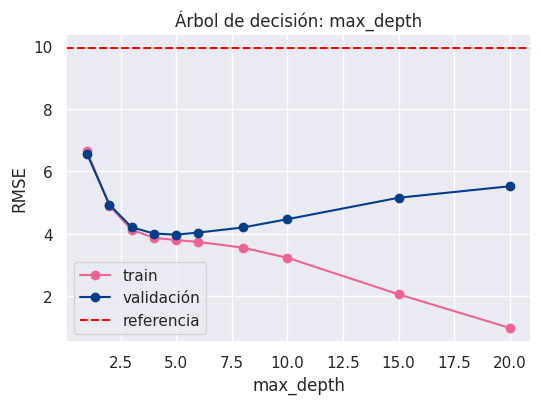

   max_depth  RMSE train  RMSE val
0          1       6.638     6.546
1          2       4.902     4.935
2          3       4.124     4.209
3          4       3.876     4.010
4          5       3.799     3.972
5          6       3.742     4.041
6          8       3.557     4.202
7         10       3.234     4.467
8         15       2.066     5.154
9         20       0.989     5.521


In [ ]:
# Variando max deth en DT
valores = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]
rmse_train = []
rmse_val = []

for d in valores:
    dt = DecisionTreeRegressor(max_depth=d, random_state=SEED)
    dt.fit(X_train, y_train)
    train=evaluar(y_train, dt.predict(X_train))["RMSE"]
    val=evaluar(y_val, dt.predict(X_val))["RMSE"]
    rmse_train.append(train)
    rmse_val.append(val)

plt.figure(figsize=(6, 4))
plt.plot(valores, rmse_train, 'o-', label='train', color="#f06292")
plt.plot(valores, rmse_val, 'o-', label='validación', color="#023e8a")
plt.axhline(ref["RMSE"], color='red', linestyle='--', label='referencia')
plt.xlabel('max_depth')
plt.ylabel('RMSE')
plt.title('Árbol de decisión: max_depth')
plt.legend()
plt.show()

print(pd.DataFrame({'max_depth': valores, 'RMSE train': rmse_train, 'RMSE val': rmse_val}).round(3))

**Decision tree**,**`max_depth`**: con profundidad 1 el modelo tiene un RSME alto en validadción. de ahi empieza a disminuir hasta max_depth=4, a partir de ahi empieza a aumnetar y en train el RSME diminuye bastante creando una gran diferencia entre train y validacion lo que indica un sobreajuste. se escoge `max_depth=4`(3.972) que es donde la metrica es menor y la diferencia entre validacion y train es pequeña.

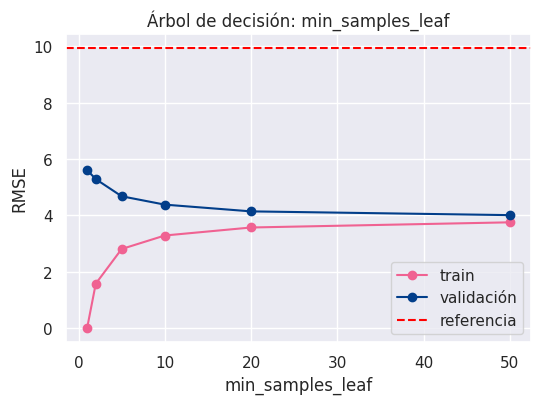

   min_samples_leaf  RMSE train  RMSE val
0                 1       0.000     5.606
1                 2       1.573     5.286
2                 5       2.804     4.676
3                10       3.284     4.380
4                20       3.568     4.140
5                50       3.752     4.007


In [ ]:
#decision tree variando min_samples_leaf
valores = [1, 2, 5, 10, 20, 50]
rmse_train = []
rmse_val = []

for m_leaf in valores:
    dt = DecisionTreeRegressor(min_samples_leaf=m_leaf, random_state=SEED)
    dt.fit(X_train, y_train)
    train=evaluar(y_train, dt.predict(X_train))["RMSE"]
    val=evaluar(y_val, dt.predict(X_val))["RMSE"]
    rmse_train.append(train)
    rmse_val.append(val)

plt.figure(figsize=(6, 4))
plt.plot(valores, rmse_train, 'o-', label='train', color="#f06292")
plt.plot(valores, rmse_val, 'o-', label='validación', color="#023e8a")
plt.axhline(ref["RMSE"], color='red', linestyle='--', label='referencia')
plt.xlabel('min_samples_leaf')
plt.ylabel('RMSE')
plt.title('Árbol de decisión: min_samples_leaf')
plt.legend()
plt.show()

print(pd.DataFrame({'min_samples_leaf': valores, 'RMSE train': rmse_train, 'RMSE val': rmse_val}).round(3))

**Decision tree**,**`min_samples_leaf`**:El mejor valor es 50 con RSME de 4.007, en min_samples_leaf=1 se ve una grab¿n diferencia entre train y validacion osea se presenta un sobreajuste y llegando a 50 la diferencia se va notando menos y el valor de la metrica en validdacion va disminuyendo

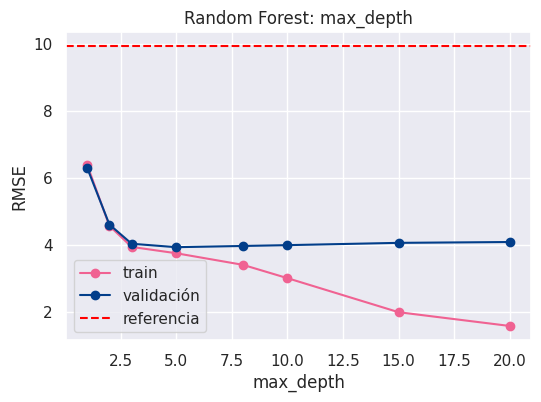

   max_depth  RMSE train  RMSE val
0          1       6.400     6.309
1          2       4.574     4.614
2          3       3.946     4.040
3          5       3.757     3.937
4          8       3.411     3.974
5         10       3.014     3.998
6         15       1.997     4.067
7         20       1.586     4.092


In [ ]:
#variando max_depth en random forest
valores = [1, 2, 3, 5, 8, 10, 15, 20]
rmse_train = []
rmse_val = []

for d in valores:
    rf = RandomForestRegressor(max_depth=d, random_state=SEED)
    rf.fit(X_train, y_train)
    train=evaluar(y_train, rf.predict(X_train))["RMSE"]
    rmse_train.append(train)
    val=evaluar(y_val, rf.predict(X_val))["RMSE"]
    rmse_val.append(val)

plt.figure(figsize=(6, 4))
plt.plot(valores, rmse_train, 'o-', label='train', color="#f06292")
plt.plot(valores, rmse_val, 'o-', label='validación',color="#023e8a")
plt.axhline(ref["RMSE"], color='red', linestyle='--', label='referencia')
plt.xlabel('max_depth')
plt.ylabel('RMSE')
plt.title('Random Forest: max_depth')
plt.legend()
plt.show()

print(pd.DataFrame({'max_depth': valores, 'RMSE train': rmse_train, 'RMSE val': rmse_val}).round(3))

**Random Forest, `max_depth`.** Con profundidad 1 el modelo es tiene RMSE val de 6,309 Nm. El error de validación baja hasta `max_depth = 5` (3,937 Nm) y luego se mantiene casi constante , mientras que el de train sigue bajando hasta 1,6 Nm: a mayor profundidad el modelo se sobreajusta. Se escoge `max_depth = 5`, que tiene el menor RMSE en validación y una diferencia pequeña con train.

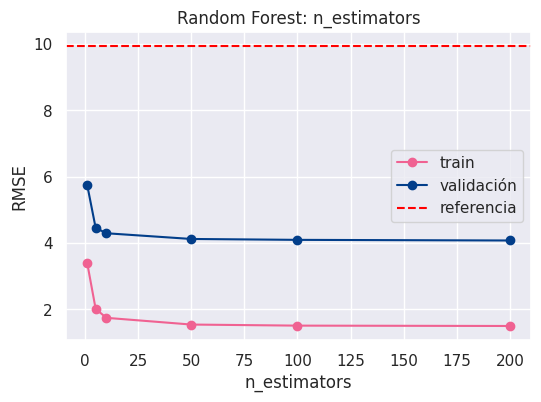

   n_estimators  RMSE train  RMSE val
0             1       3.412     5.762
1             5       2.022     4.463
2            10       1.749     4.298
3            50       1.546     4.126
4           100       1.514     4.099
5           200       1.503     4.080


In [ ]:
#variando n_stimators
valores = [1, 5, 10, 50, 100, 200]
rmse_train = []
rmse_val = []

for n in valores:
    rf = RandomForestRegressor(n_estimators=n, random_state=SEED)
    rf.fit(X_train, y_train)
    rmse_train.append(evaluar(y_train, rf.predict(X_train))["RMSE"])
    rmse_val.append(evaluar(y_val, rf.predict(X_val))["RMSE"])

plt.figure(figsize=(6, 4))
plt.plot(valores, rmse_train, 'o-', label='train', color="#f06292")
plt.plot(valores, rmse_val, 'o-', label='validación', color="#023e8a")
plt.axhline(ref["RMSE"], color='red', linestyle='--', label='referencia')
plt.xlabel('n_estimators')
plt.ylabel('RMSE')
plt.title('Random Forest: n_estimators')
plt.legend()
plt.show()

print(pd.DataFrame({'n_estimators': valores, 'RMSE train': rmse_train, 'RMSE val': rmse_val}).round(3))

**Random Forest, `n_estimators`.** Con un solo árbol el RMSE de validación es alto (5,762 Nm). Baja rápido hasta 50 árboles (4,126 Nm) y después casi no cambia: 4,099 Nm con 100 y 4,080 con 200. Agregar más árboles no produce sobreajuste, pero tampoco mejora de forma importante, y aumenta el tiempo de entrenamiento. Se escoge `n_estimators = 100`.

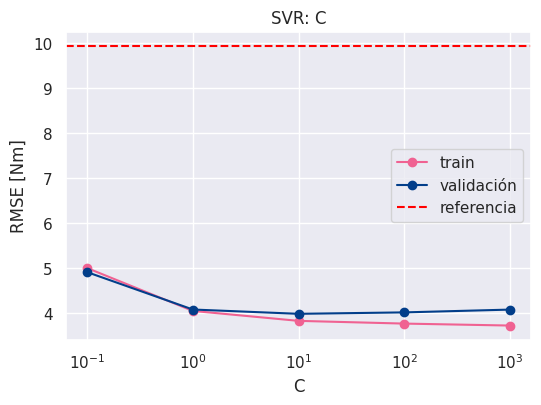

        C  RMSE train  RMSE val
0     0.1       4.997     4.907
1     1.0       4.045     4.076
2    10.0       3.824     3.980
3   100.0       3.763     4.012
4  1000.0       3.720     4.074


In [ ]:
#variando c en SVR
valores = [0.1, 1, 10, 100, 1000]
rmse_train = []
rmse_val = []

for c in valores:
    svr = make_pipeline(RobustScaler(), SVR(C=c))
    svr.fit(X_train, y_train)
    rmse_train.append(evaluar(y_train, svr.predict(X_train))["RMSE"])
    rmse_val.append(evaluar(y_val, svr.predict(X_val))["RMSE"])

plt.figure(figsize=(6, 4))
plt.plot(valores, rmse_train, 'o-', label='train', color="#f06292")
plt.plot(valores, rmse_val, 'o-', label='validación', color="#023e8a")
plt.axhline(ref["RMSE"], color='red', linestyle='--', label='referencia')
plt.xscale('log')
plt.xlabel('C')
plt.ylabel('RMSE [Nm]')
plt.title('SVR: C')
plt.legend()
plt.show()

print(pd.DataFrame({'C': valores, 'RMSE train': rmse_train, 'RMSE val': rmse_val}).round(3))

**SVR, `C`.** Con`C = 0,1`el error es alto en train y validación (4,997 y 4,907 Nm). El RMSE de validación baja hasta `C = 10` (3,980 Nm). Con`C = 100`y`C = 1000` el error de train sigue bajando,pero el de validación sube(4,012 y 4,074 Nm),lo que indica sobreajuste.Se escoge`C=10`que mejora al SVR base (`C = 1`, 4,076 Nm).

        train  validación
linear  4.927       4.846
poly    6.092       6.185
rbf     4.045       4.076


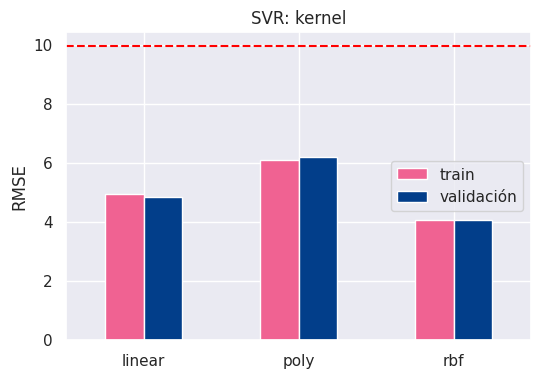

In [ ]:
#variando el kernel
kernels = ['linear', 'poly', 'rbf']
rmse_train = []
rmse_val = []

for k in kernels:
    svr = make_pipeline(RobustScaler(), SVR(kernel=k))
    svr.fit(X_train, y_train)
    rmse_train.append(evaluar(y_train, svr.predict(X_train))["RMSE"])
    rmse_val.append(evaluar(y_val, svr.predict(X_val))["RMSE"])

tabla_kernel = pd.DataFrame({'train': rmse_train, 'validación': rmse_val}, index=kernels)
print(tabla_kernel.round(3))

tabla_kernel.plot(kind='bar', figsize=(6, 4), rot=0, color=["#f06292", "#023e8a"])
plt.axhline(ref["RMSE"], color='red', linestyle='--')
plt.ylabel('RMSE')
plt.title('SVR: kernel')
plt.show()

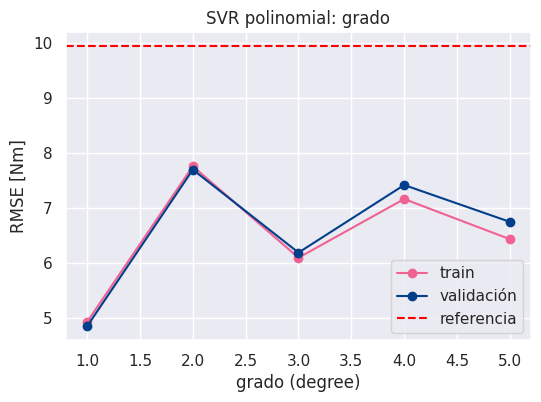

   degree  RMSE train  RMSE val
0       1       4.924     4.845
1       2       7.757     7.696
2       3       6.092     6.185
3       4       7.161     7.415
4       5       6.430     6.745


In [ ]:
#Variando degree
valores = [1, 2, 3, 4, 5]
rmse_train = []
rmse_val = []

for g in valores:
    svr = make_pipeline(RobustScaler(), SVR(kernel='poly', degree=g))
    svr.fit(X_train, y_train)
    rmse_train.append(evaluar(y_train, svr.predict(X_train))["RMSE"])
    rmse_val.append(evaluar(y_val, svr.predict(X_val))["RMSE"])

plt.figure(figsize=(6, 4))
plt.plot(valores, rmse_train, 'o-', label='train', color="#f06292")
plt.plot(valores, rmse_val, 'o-', label='validación', color="#023e8a")
plt.axhline(ref["RMSE"], color='red', linestyle='--', label='referencia')
plt.xlabel('grado (degree)')
plt.ylabel('RMSE [Nm]')
plt.title('SVR polinomial: grado')
plt.legend()
plt.show()

print(pd.DataFrame({'degree': valores, 'RMSE train': rmse_train, 'RMSE val': rmse_val}).round(3))

**SVR, kernel polinomial.** El mejor grado es 1, con un RMSE de validación de 4,845 Nm. Con grados 2 a 5 el error sube (entre 6,2 y 7,7 Nm) y no sigue una tendencia clara. Como train y validación tienen valores parecidos, el problema no es sobreajuste sino que el polinomio no logra ajustar bien los datos. Ningún grado supera al kernel RBF, por lo que el kernel polinomial se descarta.

## **Configuración elegida**

Al variar los hiperparámetros se obtuvo lo siguiente. En el **decision tree** el menor error se presenta en `max_depth = 4` y `min_samples_leaf=50`.En el **Random Forest**, el menor RMSE de validación se alcanza con `max_depth = 5` (3,937 Nm), ya que con más profundidad el error de train sigue bajando pero el de validación no mejora, osea, el modelo se sobreajusta. En el **SVR**, el mejor valor es `C = 10` (3,980 Nm), porque con `C` mayor el error de validación sube por sobreajuste, y el kernel `rbf` supera al lineal y al polinomial, cuyos mejores resultados no llegan a ese nivel. Por tanto, las configuraciones que pasan a la validación cruzada de la Fase 6 son:**Decison tree** con `max_depth = 4` y `min_samples_leaf=50`, **Random Forest** con `max_depth = 5` y `n_estimators = 100`, y **SVR** con `kernel = 'rbf'` y `C = 10`.

               RMSE train  RMSE val  R2 val
Modelo                                     
Decision tree       3.876     4.010   0.837
Random Forest       3.757     3.937   0.843
SVR                 3.824     3.980   0.840


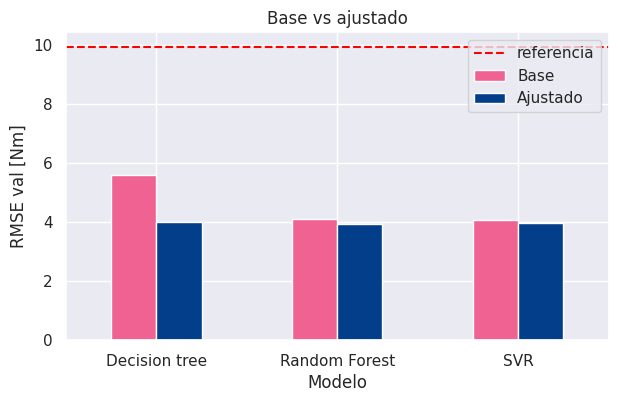

In [ ]:
dt_aj  = DecisionTreeRegressor(max_depth=4, min_samples_leaf=50, random_state=SEED)
rf_aj  = RandomForestRegressor(max_depth=5, n_estimators=100, random_state=SEED)
svr_aj = make_pipeline(RobustScaler(), SVR(kernel='rbf', C=10))

modelos_aj = {"Decision tree": dt_aj, "Random Forest": rf_aj, "SVR": svr_aj}

filas = []
for nombre, m in modelos_aj.items():
    m.fit(X_train, y_train)
    filas.append({"Modelo": nombre,
                  "RMSE train": evaluar(y_train, m.predict(X_train))["RMSE"],
                  "RMSE val":   evaluar(y_val,   m.predict(X_val))["RMSE"],
                  "R2 val":     evaluar(y_val,   m.predict(X_val))["R2"]})

tabla_ajustada = pd.DataFrame(filas).set_index("Modelo")
print(tabla_ajustada.round(3))

nombres = ["Decision tree", "Random Forest", "SVR"]
comparacion = pd.DataFrame({"Base": tabla_base.loc[nombres, "RMSE val"],
                            "Ajustado": tabla_ajustada["RMSE val"]})
comparacion.plot(kind='bar', figsize=(7, 4), rot=0, color=["#f06292", "#023e8a"])
plt.axhline(ref["RMSE"], color='red', linestyle='--', label='referencia')
plt.ylabel('RMSE val [Nm]')
plt.title('Base vs ajustado')
plt.legend()
plt.show()

Al combinar los hiperparámetros elegidos, el Decision tree baja su RMSE de validación de ≈ 5,6 a 4,010, el Random Forest de 4,099 a 3,937  y el SVR de 4,076 a 3,980 . El árbol es el que más mejora, porque sin límite de profundidad se sobreajustaba mucho. Los tres modelos quedan muy por debajo de la referencia y a menos de 0,1 Nm entre sí, por lo que en la Fase 6 se comparan con validación cruzada para decidir con más seguridad.

# **fase 6: Validación cruzada y boxplot**

Se usa un Kfold de 5 particiones sobre todos los modelos usando solo el train. En cada ronda un fold distinto hace de validación, por lo que todas las filas se usan para evaluar exactamente una vez.

En la tabla reportas media ± desviación, pero no logra evidenciar si hubo un fold atípico, ni cómo se distribuyen los 5 valores. por esa razon se hacen boxplots de las metricas.

        Referencia (media)  Decision tree  Random Forest    SVR
Fold 1               9.473          3.817          3.737  3.817
Fold 2              10.025          3.981          3.888  4.050
Fold 3              10.196          4.005          3.946  3.980
Fold 4              10.198          4.106          3.986  4.046
Fold 5              10.048          3.884          3.808  3.866


,RMSE,MAE,R2
Modelo,,,
Referencia (media),9.988 ± 0.267,7.978 ± 0.242,-0.000 ± 0.000
Decision tree,3.959 ± 0.100,3.023 ± 0.093,0.843 ± 0.005
Random Forest,3.873 ± 0.091,2.933 ± 0.083,0.850 ± 0.004
SVR,3.952 ± 0.095,2.976 ± 0.094,0.843 ± 0.006


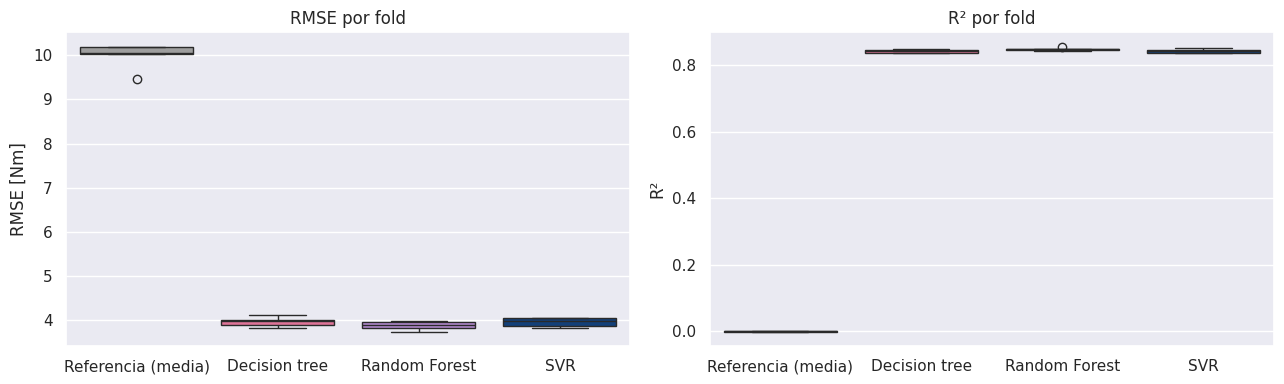

In [ ]:
# Validación cruzada

paleta = {
    "Referencia (media)": "#9e9e9e",
    "Decision tree": "#f06292",
    "Random Forest": "#b57edc",
    "SVR": "#023e8a",
}

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
modelos_cv = {
    "Referencia (media)": DummyRegressor(strategy="mean"),
    "Decision tree": dt_aj,
    "Random Forest": rf_aj,
    "SVR": svr_aj,
}

metricas = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}
resultados = {}
for nombre, modelo in modelos_cv.items():
    cv = cross_validate(modelo, X_train, y_train, cv=kf, scoring=metricas)
    resultados[nombre] = {
        "RMSE": -cv["test_rmse"],
        "MAE": -cv["test_mae"],
        "R2": cv["test_r2"],
    }

rmse_fold = pd.DataFrame({nombre: r["RMSE"] for nombre, r in resultados.items()})
rmse_fold.index = [f"Fold {i}" for i in range(1, 6)]
print(rmse_fold.round(3))

filas = []
for nombre, r in resultados.items():
    filas.append({
        "Modelo": nombre,
        "RMSE": f"{r['RMSE'].mean():.3f} ± {r['RMSE'].std():.3f}",
        "MAE": f"{r['MAE'].mean():.3f} ± {r['MAE'].std():.3f}",
        "R2": f"{r['R2'].mean():.3f} ± {r['R2'].std():.3f}",
    })
tabla_cv = pd.DataFrame(filas).set_index("Modelo")
display(tabla_cv)

r2_folds = pd.DataFrame({nombre: r["R2"] for nombre, r in resultados.items()})
colores_cv = [paleta[n] for n in modelos_cv]
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))

#Boxplots

sns.boxplot(data=rmse_fold, palette=colores_cv, ax=ejes[0])
ejes[0].set_title("RMSE por fold")
ejes[0].set_ylabel("RMSE [Nm]")

sns.boxplot(data=r2_folds, palette=colores_cv, ax=ejes[1])
ejes[1].set_title("R² por fold")
ejes[1].set_ylabel("R²")

plt.tight_layout()
plt.show()
print("\n")

Con 5 folds sobre el conjunto de entrenamiento, el Decision tree obtuvo un RMSE de 3.959 ± 0.100 Nm, un MAE de 3.023 ± 0.093 Nm y un R² de 0.843 ± 0.005. El Random Forest obtuvo un RMSE de 3,873 ± 0,091 Nm, un MAE de 2,933 ± 0,083 Nm y un R² de 0,850 ± 0,004. El SVR obtuvo un RMSE de 3,952 ± 0,095 Nm, un MAE de 2,976 ± 0,094 Nm y un R² de 0,843 ± 0,006.

Los tres modelos reducen el error de la referencia en torno a un 60 % en todos los folds, y sus desviaciones son pequeñas, así que el resultado no depende de la partición elegida.

# **Fase 7: Elección del mejor modelo**

Se comparan los modelos con su mejor hiperparametro en el conjunto de validación, se elige el el de mejor RMSE y si hay empate aplicar la regla de la fase 2. Ademas, el MAE del ganador debe ser bajo y el $R^2$ alto.



Referencia (media): RMSE val = 9.942


,RMSE train,RMSE val,MAE val,R2 val
Modelo,,,,
Decision tree,3.876,4.010,3.074,0.837
Random Forest,3.757,3.937,3.001,0.843
SVR,3.824,3.980,3.022,0.840


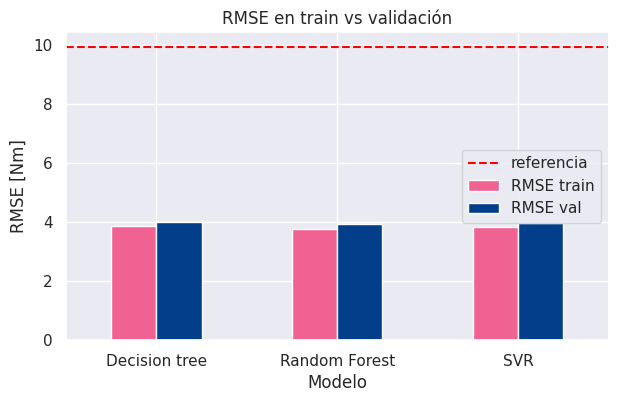

In [ ]:
# Entrenamiento y validación

modelos_finales = {
    "Decision tree": dt_aj,
    "Random Forest": rf_aj,
    "SVR": svr_aj,
}
nombres = list(modelos_finales)
colores = [paleta[n] for n in nombres]

filas = []
for nombre, modelo in modelos_finales.items():
    modelo.fit(X_train, y_train)
    r_tr = evaluar(y_train, modelo.predict(X_train))
    r_val = evaluar(y_val, modelo.predict(X_val))
    filas.append({
        "Modelo": nombre,
        "RMSE train": r_tr["RMSE"],
        "RMSE val": r_val["RMSE"],
        "MAE val": r_val["MAE"],
        "R2 val": r_val["R2"],
    })

tabla_val = pd.DataFrame(filas).set_index("Modelo")
print("Referencia (media): RMSE val =", round(ref["RMSE"], 3))
display(tabla_val.round(3))

tabla_val[["RMSE train", "RMSE val"]].plot(
    kind="bar", figsize=(7, 4), rot=0, color=["#f06292", "#023e8a"])
plt.axhline(ref["RMSE"], color="red", linestyle="--", label="referencia")
plt.ylabel("RMSE [Nm]")
plt.title("RMSE en train vs validación")
plt.legend()
plt.show()


,RMSE media,RMSE std,MAE media,R2 media
Modelo,,,,
Decision tree,3.959,0.100,3.023,0.843
Random Forest,3.873,0.091,2.933,0.850
SVR,3.952,0.095,2.976,0.843


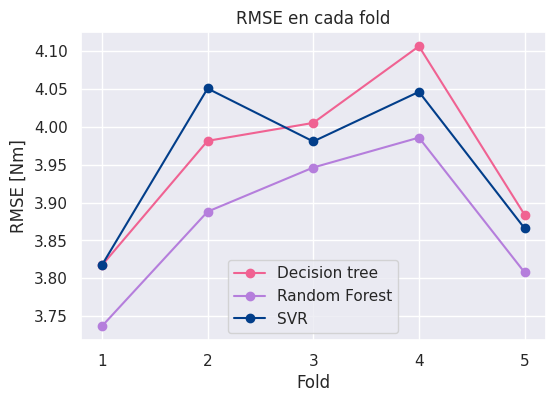



Decision tree tiene el menor RMSE en 0 de 5 folds
Random Forest tiene el menor RMSE en 5 de 5 folds
SVR tiene el menor RMSE en 0 de 5 folds


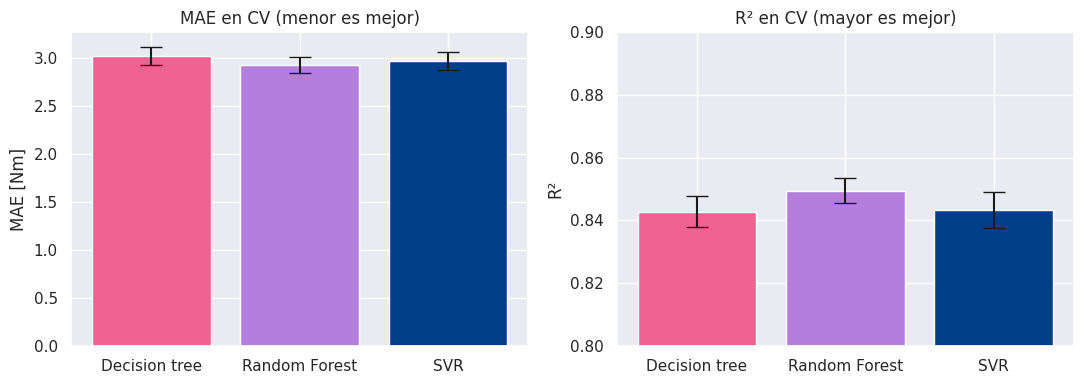

In [ ]:
# RMSE, MAE y R² de cada modelo por fold

filas = []
for nombre in nombres:
    r = resultados[nombre]
    filas.append({
        "Modelo": nombre,
        "RMSE media": r["RMSE"].mean(),
        "RMSE std": r["RMSE"].std(),
        "MAE media": r["MAE"].mean(),
        "R2 media": r["R2"].mean(),
    })

tabla_cv_num = pd.DataFrame(filas).set_index("Modelo")
display(tabla_cv_num.round(3))

folds = [1, 2, 3, 4, 5]

plt.figure(figsize=(6, 4))
for nombre, color in zip(nombres, colores):
    plt.plot(folds, resultados[nombre]["RMSE"], "o-", label=nombre, color=color)
plt.xticks(folds)
plt.xlabel("Fold")
plt.ylabel("RMSE [Nm]")
plt.title("RMSE en cada fold")
plt.legend()
plt.show()
print("\n")

rmse_por_fold = pd.DataFrame({n: resultados[n]["RMSE"] for n in nombres})
victorias = rmse_por_fold.idxmin(axis=1).value_counts().reindex(nombres, fill_value=0)
for nombre, v in victorias.items():
    print(f"{nombre} tiene el menor RMSE en {v} de 5 folds")

mae_media = [resultados[n]["MAE"].mean() for n in nombres]
mae_std = [resultados[n]["MAE"].std() for n in nombres]
r2_media = [resultados[n]["R2"].mean() for n in nombres]
r2_std = [resultados[n]["R2"].std() for n in nombres]

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].bar(nombres, mae_media, yerr=mae_std, capsize=8, color=colores)
ejes[0].set_title("MAE en CV (menor es mejor)")
ejes[0].set_ylabel("MAE [Nm]")

ejes[1].bar(nombres, r2_media, yerr=r2_std, capsize=8, color=colores)
ejes[1].set_title("R² en CV (mayor es mejor)")
ejes[1].set_ylabel("R²")
ejes[1].set_ylim(0.8, 0.9)

plt.tight_layout()
plt.show()

En promedio, el RMSE en validación cruzada es de 4.010 Nm en el Decision tree, 3,973 Nm en el Random Forest y 3,980 Nm en el SVR.

En MAE (árbol 3.074, RF 3.001, SVR 3.022) y R² (árbol 0.837, RF 0,843, SVR 0,840) las barras de error están muy cerca entre sí.

Mayor std entre folds: 0.100 Nm
Diferencia de RMSE con el mejor modelo [Nm]:
Modelo
Decision tree    0.086
Random Forest    0.000
SVR              0.079

Empate en RMSE entre: Decision tree, Random Forest, SVR
Se desempata con el MAE medio. Gana: Random Forest


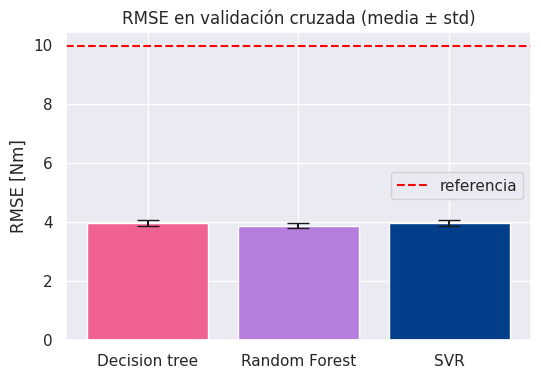

In [ ]:
# Desempate

mejor_rmse = tabla_cv_num["RMSE media"].min()
std_max = tabla_cv_num["RMSE std"].max()

diferencia = tabla_cv_num["RMSE media"] - mejor_rmse
empatados = diferencia[diferencia < std_max].index.tolist()

print(f"Mayor std entre folds: {std_max:.3f} Nm")
print("Diferencia de RMSE con el mejor modelo [Nm]:")
print(diferencia.round(3).to_string())
print()

if len(empatados) == 1:
    ganador = empatados[0]
    print("Solo un modelo queda fuera del ruido -> gana por RMSE:", ganador)
else:
    ganador = tabla_cv_num.loc[empatados, "MAE media"].idxmin()
    print("Empate en RMSE entre:", ", ".join(empatados))
    print("Se desempata con el MAE medio. Gana:", ganador)

plt.figure(figsize=(6, 4))
plt.bar(tabla_cv_num.index, tabla_cv_num["RMSE media"],
        yerr=tabla_cv_num["RMSE std"], capsize=8, color=colores)
plt.axhline(ref["RMSE"], color="red", linestyle="--", label="referencia")
plt.ylabel("RMSE [Nm]")
plt.title("RMSE en validación cruzada (media ± std)")
plt.legend()
plt.show()
print("\n")

El mejor RMSE medio en validación cruzada es el del Random Forest (3,873 Nm). El Decision tree queda a 0.086 Nm y el SVR a 0,079 Nm, y la mayor desviación entre folds es 0.100 Nm. Como esas diferencias son menores que el ruido, los tres quedan empatados en RMSE y se desempata con el MAE medio, que es menor en el Random Forest, por eso gana el Random Forest.

Ganador: Random Forest
MAE medio CV: 2.933 Nm
R2 medio CV:  0.85
Brecha RMSE val - RMSE train: 0.18 Nm
Modelo ganador: Random Forest
RMSE val: 3.937 Nm




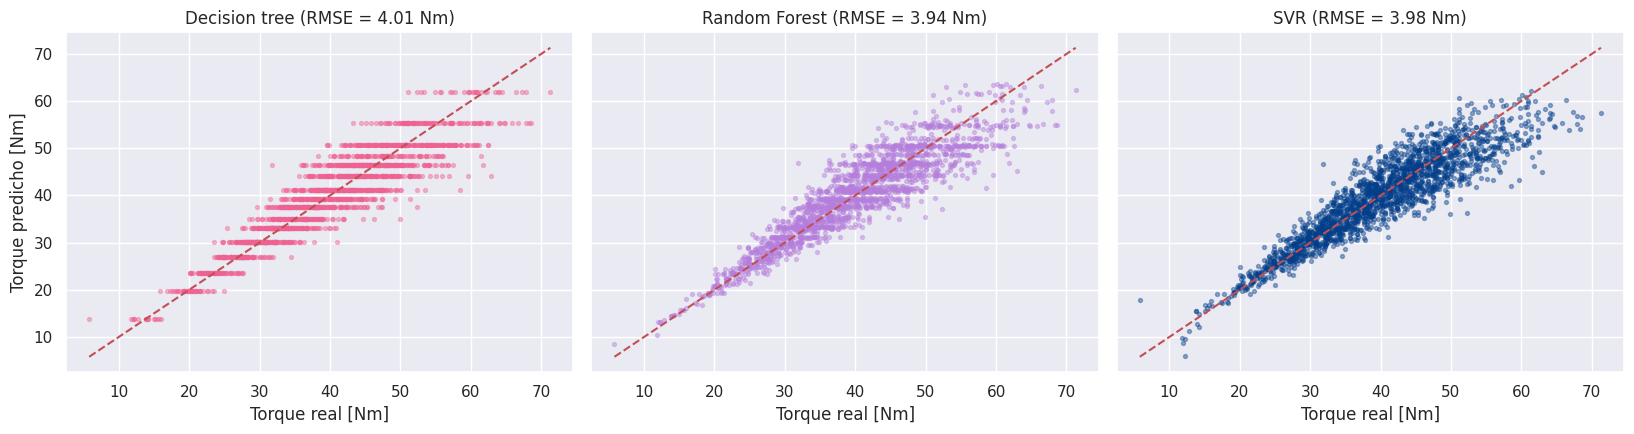

In [ ]:
# Identificando el mejor modelo

print("Ganador:", ganador)
print("MAE medio CV:", round(tabla_cv_num.loc[ganador, "MAE media"], 3), "Nm")
print("R2 medio CV: ", round(tabla_cv_num.loc[ganador, "R2 media"], 3))

brecha = tabla_val.loc[ganador, "RMSE val"] - tabla_val.loc[ganador, "RMSE train"]
print("Brecha RMSE val - RMSE train:", round(brecha, 3), "Nm")

modelo_ganador = clone(modelos_finales[ganador])
modelo_ganador.fit(X_train, y_train)

print("Modelo ganador:", ganador)
print("RMSE val:", round(evaluar(y_val, modelo_ganador.predict(X_val))["RMSE"], 3), "Nm")
print("\n")

fig, ejes = plt.subplots(1, len(nombres), figsize=(5.5 * len(nombres), 4.5), sharey=True)

for eje, nombre, color in zip(ejes, nombres, colores):
    pred = modelos_finales[nombre].predict(X_val)
    eje.scatter(y_val, pred, s=8, alpha=0.4, color=color)
    eje.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], "r--")
    eje.set_title(f"{nombre} (RMSE = {evaluar(y_val, pred)['RMSE']:.2f} Nm)")
    eje.set_xlabel("Torque real [Nm]")

ejes[0].set_ylabel("Torque predicho [Nm]")
plt.tight_layout()
plt.show()

El ganador es el Random Forest, con MAE de 2,933 Nm y R² de 0,850 en validación cruzada. La brecha entre validación y train es de 0,18 Nm, así que no está sobreajustado. En las gráficas, los tres modelos siguen la línea punteada con una dispersión parecida.Se elige el Random Forest, aunque el SVR y el árbol estuvieran cerca.

#**Fase 8: Evaluación del modelo ganador**

En esta fase se mira **dónde** se equivoca y **por qué**. Se usa el modelo ganador (`modelo_ganador`), entrenado solo con train, y se evalúa en validación. El test no se toca hasta la Fase 9.

In [ ]:
# Predicción del ganador (real - predicho)

pred_val = modelo_ganador.predict(X_val)
residuales = y_val - pred_val

print("Modelo:", ganador)
print("Media de los residuales:", round(residuales.mean(), 3), "Nm")
print("Desviación de los residuales:", round(residuales.std(), 3), "Nm")
print("Residual más negativo:", round(residuales.min(), 2), "Nm | más positivo:", round(residuales.max(), 2), "Nm")
print("Máquinas con error de hasta 5 Nm: ", round((residuales.abs() <= 5).mean() * 100, 1), "%")
print("Máquinas con error de hasta 10 Nm:", round((residuales.abs() <= 10).mean() * 100, 1), "%")

Modelo: Random Forest
Media de los residuales: 0.032 Nm
Desviación de los residuales: 3.938 Nm
Residual más negativo: -15.17 Nm | más positivo: 17.77 Nm
Máquinas con error de hasta 5 Nm:  81.2 %
Máquinas con error de hasta 10 Nm: 98.0 %


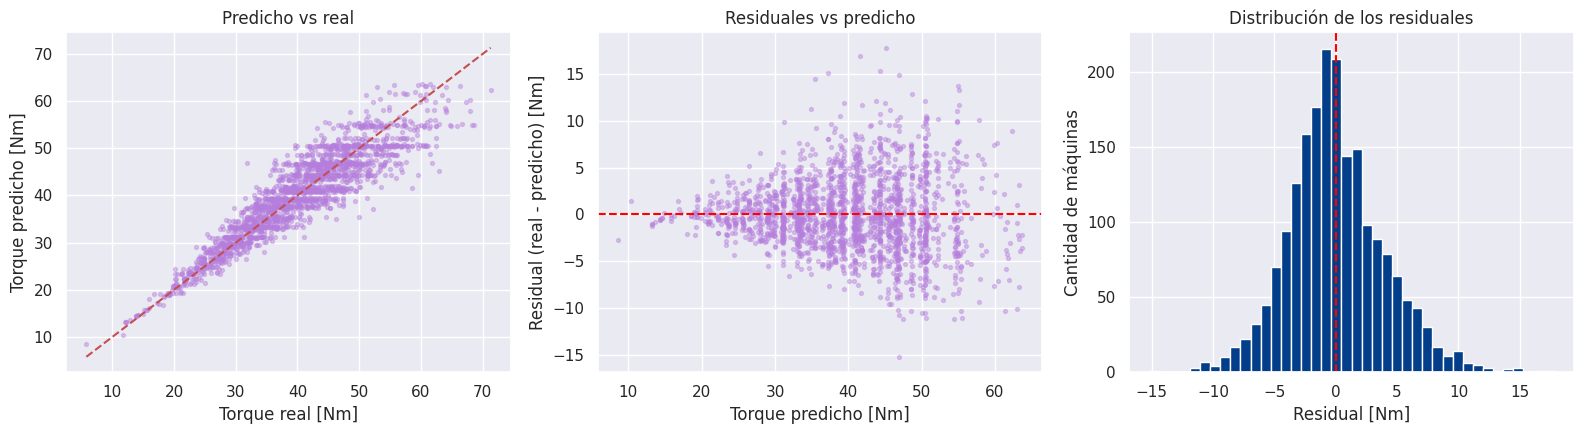

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))

# Predicho vs real
ejes[0].scatter(y_val, pred_val, s=8, alpha=0.4, color=colores[1])
ejes[0].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], "r--")
ejes[0].set_xlabel("Torque real [Nm]")
ejes[0].set_ylabel("Torque predicho [Nm]")
ejes[0].set_title("Predicho vs real")

ejes[1].scatter(pred_val, residuales, s=8, alpha=0.4, color=colores[1])
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set_xlabel("Torque predicho [Nm]")
ejes[1].set_ylabel("Residual (real - predicho) [Nm]")
ejes[1].set_title("Residuales vs predicho")

# Histograma de residuales
ejes[2].hist(residuales, bins=40, color=colores[2])
ejes[2].axvline(0, color="red", linestyle="--")
ejes[2].set_xlabel("Residual [Nm]")
ejes[2].set_ylabel("Cantidad de máquinas")
ejes[2].set_title("Distribución de los residuales")

plt.tight_layout()
plt.show()

,n,residual_medio,MAE
rango,,,
menos de 25,136,-0.68,1.21
25-35,494,-1.03,2.13
35-45,743,-0.94,2.98
45-55,494,1.26,3.52
más de 55,133,5.58,6.29


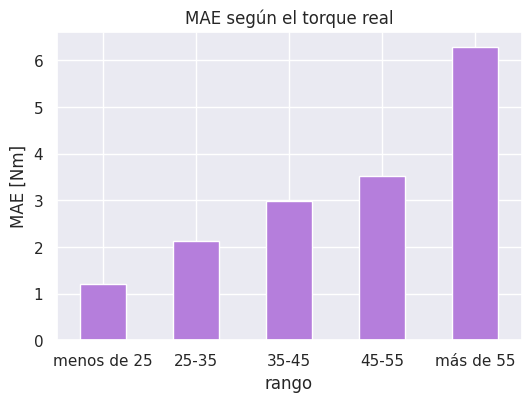

In [ ]:
# Agrupar las maquinas segun el torque
rangos = pd.cut(y_val, bins=[0, 25, 35, 45, 55, 100],
                labels=["menos de 25", "25-35", "35-45", "45-55", "más de 55"])

tabla_rangos = pd.DataFrame({"rango": rangos,
                             "residual": residuales,
                             "error_abs": residuales.abs()})

tabla_rangos = tabla_rangos.groupby("rango", observed=True).agg(
    n=("residual", "count"),
    residual_medio=("residual", "mean"),
    MAE=("error_abs", "mean")).round(2)
display(tabla_rangos)

tabla_rangos["MAE"].plot(kind="bar", figsize=(6, 4), rot=0, color=colores[1])
plt.ylabel("MAE [Nm]")
plt.title("MAE según el torque real")
plt.show()

,n,MAE
Sin falla (0),1940,2.908
Con falla (1),60,6.003


,n,MAE
Type,,
H,184,2.878
L,1208,2.927
M,608,3.185


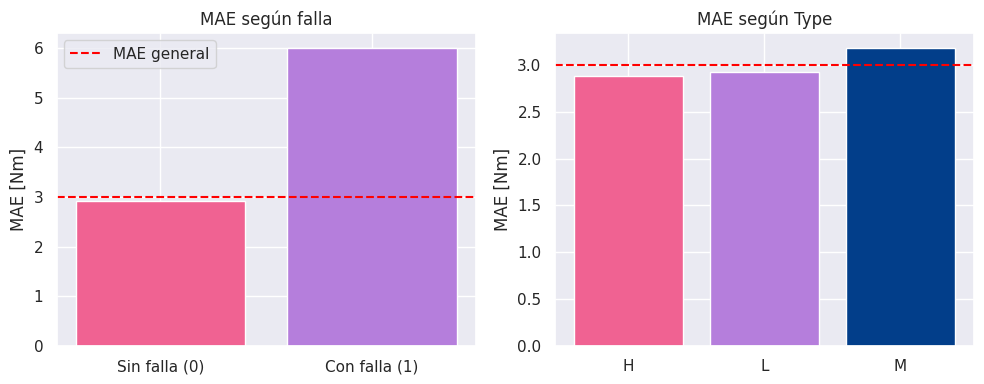

In [ ]:
# Tabla con el error absoluto de cada máquina y sus grupos
grupos = pd.DataFrame({
    "real": y_val,
    "pred": pred_val,
    "Target": target_aux.loc[y_val.index],
    "Type": df.loc[y_val.index, "Type"]})
grupos["error_abs"] = (grupos["real"] - grupos["pred"]).abs()

# Según si falla
mae_target = grupos.groupby("Target")["error_abs"].agg(["count", "mean"])
mae_target.columns = ["n", "MAE"]
mae_target.index = ["Sin falla (0)", "Con falla (1)"]

# Según el tipo de falla
mae_type = grupos.groupby("Type")["error_abs"].agg(["count", "mean"])
mae_type.columns = ["n", "MAE"]

display(mae_target.round(3))
display(mae_type.round(3))

mae_general = evaluar(y_val, pred_val)["MAE"]
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].bar(mae_target.index, mae_target["MAE"], color=colores[:2])
ejes[0].set_title("MAE según falla")
ejes[1].bar(mae_type.index, mae_type["MAE"], color=colores)
ejes[1].set_title("MAE según Type")
for eje in ejes:
    eje.axhline(mae_general, color="red", linestyle="--", label="MAE general")
    eje.set_ylabel("MAE [Nm]")
ejes[0].legend()
plt.tight_layout()
plt.show()

Rotational speed [rpm]     0.9960
Tool wear [min]            0.0015
Air temperature [K]        0.0009
Temp_diff                  0.0009
Process temperature [K]    0.0006
Type_H                     0.0001
Type_L                     0.0001
Type_M                     0.0000
dtype: float64


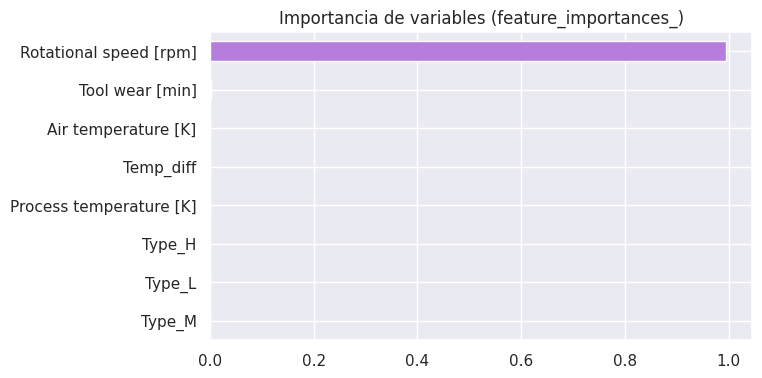

In [ ]:

if hasattr(modelo_ganador, "feature_importances_"):
    importancia = pd.Series(modelo_ganador.feature_importances_, index=X_train.columns)
    titulo = "Importancia de variables (feature_importances_)"
else:
    r = permutation_importance(modelo_ganador, X_val, y_val,
                               scoring="neg_root_mean_squared_error",
                               n_repeats=10, random_state=SEED)
    importancia = pd.Series(r.importances_mean, index=X_train.columns)
    titulo = "Importancia por permutación"

importancia = importancia.sort_values()
print(importancia.sort_values(ascending=False).round(4))

importancia.plot.barh(figsize=(7, 4), color="#b57edc")
plt.title(titulo)
plt.show()

Rotational speed [rpm]     9.5357
Process temperature [K]    0.0005
Type_M                    -0.0000
Type_H                    -0.0002
Type_L                    -0.0004
Air temperature [K]       -0.0028
Temp_diff                 -0.0046
Tool wear [min]           -0.0060
dtype: float64


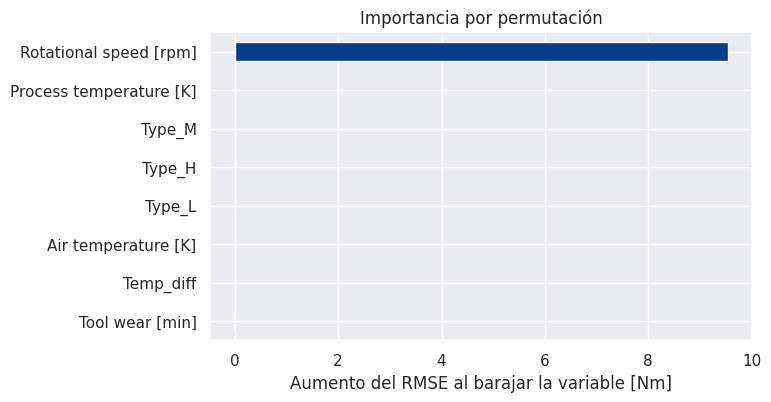

In [ ]:
# Importancia por permutación en validación

r = permutation_importance(modelo_ganador, X_val, y_val,
                           scoring="neg_root_mean_squared_error",
                           n_repeats=10, random_state=SEED)
perm = pd.Series(r.importances_mean, index=X_train.columns).sort_values()
print(perm.sort_values(ascending=False).round(4))

perm.plot.barh(figsize=(7, 4), color="#023e8a")
plt.xlabel("Aumento del RMSE al barajar la variable [Nm]")
plt.title("Importancia por permutación")
plt.show()

#**Fase 9: Evaluación en el test**

In [ ]:
#Reentrenamiento

modelo_final = clone(modelos_finales[ganador])
modelo_final.fit(X_tv, y_tv)

pred_test = modelo_final.predict(X_test)
res_test = evaluar(y_test, pred_test)

ref_test = evaluar(y_test, np.full(len(y_test), y_tv.mean()))
tabla_test = pd.DataFrame([ref_test, res_test], index=["Referencia (media)", ganador])
print("Resultados en test:")
display(tabla_test.round(3))

Resultados en test:


,RMSE,MAE,R2
Referencia (media),9.928,7.905,-0.000
Random Forest,4.002,2.987,0.838


In [ ]:
# Comparar el RMSE de test, validación y validación cruzada
rmse_val = tabla_val.loc[ganador, "RMSE val"]
rmse_cv = tabla_cv_num.loc[ganador, "RMSE media"]
std_cv = tabla_cv_num.loc[ganador, "RMSE std"]
rmse_test = res_test["RMSE"]

print("RMSE en validación:", round(rmse_val, 3), "Nm")
print("RMSE en test:      ", round(rmse_test, 3), "Nm")
print("Diferencia (test - validación):", round(rmse_test - rmse_val, 3), "Nm")
print("RMSE en validación cruzada:", round(rmse_cv, 3), "±", round(std_cv, 3), "Nm")
print("RMSE en test con el valor de referencia:", round(ref_test["RMSE"], 3), "Nm")

# Residuales (real - predicho)
residuales_test = y_test - pred_test
print("\nMedia de los residuales:", round(residuales_test.mean(), 3), "Nm")
print("Desviación de los residuales:", round(residuales_test.std(), 3), "Nm")
print("Máquinas con error de hasta 5 Nm: ", round((residuales_test.abs() <= 5).mean() * 100, 1), "%")
print("Máquinas con error de hasta 10 Nm:", round((residuales_test.abs() <= 10).mean() * 100, 1), "%")

RMSE en validación: 3.937 Nm
RMSE en test:       4.002 Nm
Diferencia (test - validación): 0.064 Nm
RMSE en validación cruzada: 3.873 ± 0.091 Nm
RMSE en test con el valor de referencia: 9.928 Nm

Media de los residuales: -0.011 Nm
Desviación de los residuales: 4.003 Nm
Máquinas con error de hasta 5 Nm:  82.7 %
Máquinas con error de hasta 10 Nm: 97.7 %


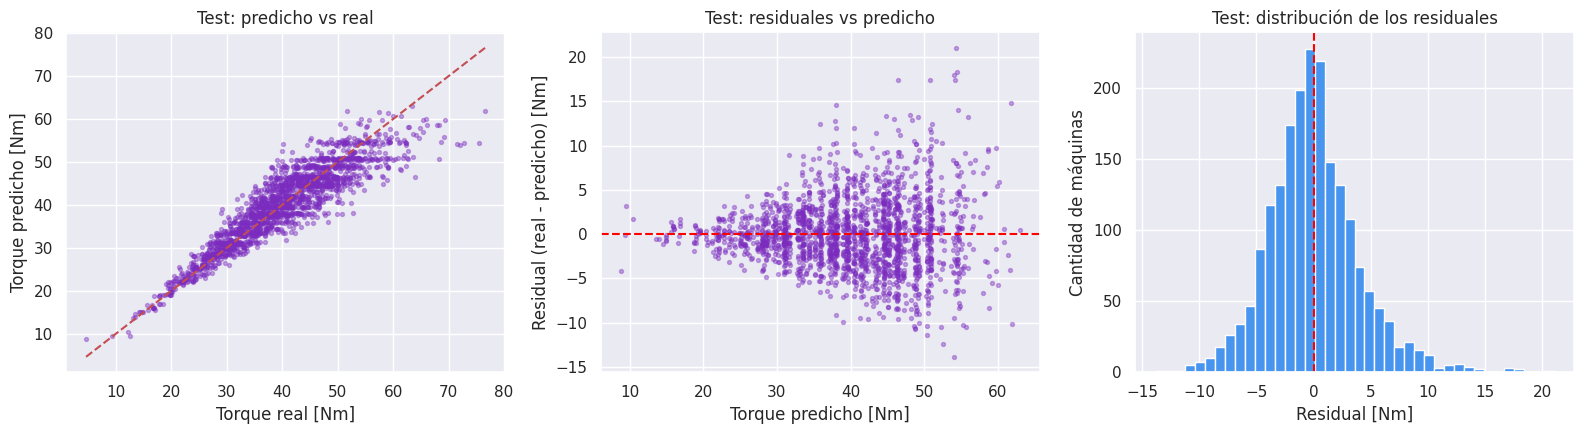

In [ ]:

color_puntos = "#7b2cbf"
color_hist = "#4895ef"

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))

# Predicho vs real
ejes[0].scatter(y_test, pred_test, s=8, alpha=0.4, color=color_puntos)
ejes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
ejes[0].set_xlabel("Torque real [Nm]")
ejes[0].set_ylabel("Torque predicho [Nm]")
ejes[0].set_title("Test: predicho vs real")

ejes[1].scatter(pred_test, residuales_test, s=8, alpha=0.4, color=color_puntos)
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set_xlabel("Torque predicho [Nm]")
ejes[1].set_ylabel("Residual (real - predicho) [Nm]")
ejes[1].set_title("Test: residuales vs predicho")

# Histograma de residuales
ejes[2].hist(residuales_test, bins=40, color=color_hist)
ejes[2].axvline(0, color="red", linestyle="--")
ejes[2].set_xlabel("Residual [Nm]")
ejes[2].set_ylabel("Cantidad de máquinas")
ejes[2].set_title("Test: distribución de los residuales")

plt.tight_layout()
plt.show()

###Observación:

Aunque esta grafia pretenda ser muy parecida a la de la fase 8, lo cierto es que lo que se busca es que los resultados del test lleguen o se acerquen a los de validación que tiene un ajuste positivo. Pero, aun así en los resultados del test podemos ver en las graficas la diferencia principal es que el test incluye máquinas con torque real de 70 a 77 Nm, que el modelo predice en 54 a 62 Nm, eso genera residuales de +15 a +21 Nm, más grandes que los de validación.

#**Conclusiones**


*   El proyecto demuestra que es posible predecir el torque de la máquina con una alta precisión utilizando únicamente las condiciones de operación. Los tres modelos finales reducen el RMSE de validación desde ~9.94 Nm (referencia) hasta ~3.9–4.0 Nm, lo cual es una mejora sustancial. Sin embargo, la correlación de Rotational speed [rpm] con el torque es de -0.875, muy superior al resto. Esto sugiere que buena parte del R² ≈ 0.84–0.85 podría explicarse por esa única variable.


*   El RMSE medio en validación cruzada fue 3.873 (RF), 3.952 (SVR) y 3.959 (árbol), con una desviación máxima entre folds de 0.100 Nm. Se aplicó una regla de desempate por MAE, lo cual es razonable, pero conviene reconocer que los tres modelos son prácticamente equivalentes en rendimiento. Elegir Random Forest es defendible, pero no implica que sea categóricamente superior; un SVR o un arbol de desición podrían ser preferibles en contextos donde se priorice interpretabilidad o velocidad de inferencia.




*   El hecho de que la desviación entre folds sea baja (≈0.1 Nm) y que el orden de los modelos se mantenga en los cinco folds es una señal positiva. Significa que el rendimiento es reproducible y que el modelo no está "haciendo trampa" en un conjunto específico.

*   La distribución de residuales centrada en cero, con el 81.2% de predicciones dentro de ±5 Nm y el 98% dentro de ±10 Nm, indica que el modelo no tiene sesgo sistemático y que sus errores son, en su mayoría, pequeños. Las gráficas de predicho vs real y de residuales vs predicho permiten observar esto.





*   El dataset suele usarse para clasificar fallos (Target, Failure Type), pero este proyecto lo aprovecha para predecir una variable continua como Torque [Nm]. El modelo ganador (Random Forest) redujo el RMSE de validación de ~9.94 Nm (referencia de la media) a 3.937 Nm, una mejora de más del 60%. En validación cruzada de 5 folds, el RMSE medio fue de 3.873 ± 0.091 Nm y el MAE medio de 2.933 ± 0.083 Nm, con un R² de 0.850 ± 0.004.


